# ViZDoom Defend the Center: PPO with AgileRL

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tpoff/rl-epsilon/blob/main/vizdoom-experiments/defend-the-center-ppo-AgileRL/AgileRL_PPO_DoomDefendTheCenter_TrainEval.ipynb)

In this notebook we'll train a PPO agent with AgileRL to take on the "Defend the Center" scenario in ViZDoom, again using only visual observations. The earlier notebooks in this series used DQN, so this is a good chance to see how a different kind of algorithm handles a similar setup.

PPO (Proximal Policy Optimization) works quite differently from DQN. Instead of learning how good each action is and picking the best one, it learns the policy directly, as a probability for each action. It collects a batch of fresh experience with its current policy, takes a few careful learning steps on it, then throws the batch away and collects a new one. That means no replay buffer and no epsilon schedule, since the agent explores just by sampling from its own action probabilities.

Defend the Center drops Doomguy in the middle of a circular room with a pistol and only 26 bullets, while enemies close in from every side. All he can do is turn and shoot, so the agent has to learn to find enemies, line up its shots and not waste ammo.

As with Deadly Corridor, the agent trains on the stock scenario, but evaluation and recording use a custom version I made, `defend_the_center_outro`. It's identical except that the episode doesn't end the instant Doomguy dies or the clock runs out. Instead the game freezes for a couple of seconds, and if he died it plays Doomguy's death animation: his weapon drops and the view sinks to the floor, just like in the original game. That makes for much nicer videos.

This notebook walks through setting up the environment with some light reward shaping, setting up the PPO agent (including the same hack from the DQN notebooks to gather metrics during training), and setting up ViZDoom with either the original Doom WADs or the bundled Freedoom WADs. Then we train the agent and evaluate its performance! Should be fun!

# Setup
First we'll install everything and define all the configuration for our experiment.

## Install Dependencies
If we're on Colab we'll need to grab OpenAL first, since ViZDoom needs it to run there, then install everything with pip. I pinned the versions so the notebook doesn't break the next time one of these libraries pushes an update. If you're running locally and already have everything installed, you can skip this cell.

In [1]:
import sys

# test if we're on colab, if we are update some packages
if "google.colab" in sys.modules:
    !apt-get update -qq
    !apt-get install -y -qq libopenal1 libopenal-dev > /dev/null

# install all the python packages we'll need
%pip install -q vizdoom==1.3.1 agilerl==2.8.4 gymnasium==1.3.0 imageio==2.38.0 imageio-ffmpeg==0.6.0 opencv-python==5.0.0.93 scipy==1.17.1 numpy==2.4.6 pandas==3.0.5 torch==2.13.0 matplotlib==3.11.1

Note: you may need to restart the kernel to use updated packages.


## Imports
To make the notebook read a bit nicer we'll go ahead and import everything we'll need in this cell.

In [2]:
import json
import os
import shutil
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import gymnasium
import imageio.v2 as imageio
import imageio_ffmpeg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch


from agilerl.algorithms.ppo import PPO
from agilerl.training.train_on_policy import train_on_policy
from gymnasium.spaces import Box
from gymnasium.wrappers import FrameStackObservation, ResizeObservation, TransformObservation
from IPython.display import Image, display
from scipy.io import wavfile


import vizdoom as vzd
from vizdoom import gymnasium_wrapper  # registers the Vizdoom* gymnasium envs
from vizdoom.gymnasium_wrapper.base_gymnasium_env import VizdoomEnv

/opt/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuration
These are the main knobs for the environment, the reward shaping and evaluation. The environment setup is the same as the DQN notebooks: the agent picks an action every 4 frames, and it sees the last 4 frames stacked together (shrunk down to 84x84) so it can get a sense of motion. Defend the Center only has 3 buttons (turn left, turn right and attack), and we let the agent press up to 2 at once so it can turn and shoot at the same time. That gives it 7 actions to pick from. We run 16 environments side by side, which PPO really benefits from, since every update learns from a fresh batch collected across all of them.

`AMMO_PENALTY` and `DAMAGE_PENALTY` control the reward shaping, more on that in the Environment section. `EVAL_EPISODES`, `TEST_EPISODES` and `RECORD_EPISODES` control how many episodes we run when scoring each checkpoint, testing the best model and recording videos. `RECORD_CHECKPOINTS` can be set to `"all"` if you want videos of every generation, but heads up, converting them all takes a while!

In [3]:
ENV_NAME = "VizdoomDefendCenter-v1"
NUM_ENVS = 16
FRAME_SKIP = 4
STACK_SIZE = 4
OBS_SIZE = (84, 84)
MAX_BUTTONS_PRESSED = 2
AMMO_PENALTY = 0.05    # penalty per bullet fired
DAMAGE_PENALTY = 0.01  # penalty per point of health lost

EVAL_EPISODES = 4
TEST_EPISODES = 5
RECORD_EPISODES = 3
RECORD_CHECKPOINTS = "best"  # "best" or "all"

## Files and Paths
All the logic for finding and saving files lives in this section, so the rest of the notebook doesn't have to care where it's running.

### Where We're Running
On Colab, `USE_DRIVE` keeps everything in Google Drive so the results stick around after the session ends, otherwise everything runs out of the notebook's own folder.

In [4]:
USE_DRIVE = True      # Colab only: keep the experiment (and every output) in Google Drive
EXPERIMENT = "defend-the-center-ppo-AgileRL"

if "google.colab" in sys.modules and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    experiment_dir = Path("/content/drive/MyDrive/rl-epsilon/vizdoom-experiments") / EXPERIMENT
elif "google.colab" in sys.modules:
    experiment_dir = Path("/content") / EXPERIMENT  # lost when the Colab session ends
else:
    experiment_dir = Path.cwd()  # local: the notebook's own folder
print("experiment:", experiment_dir)

experiment: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-center-ppo-AgileRL


### Scenario and WAD
By default ViZDoom loads Freedoom assets, which are free replacements for the Doom characters and levels, but it's possible to use the original Doom assets instead by loading the WAD file. If `DOOM2.WAD` is sitting in the `WADS` folder we'll use it, otherwise ViZDoom falls back to Freedoom, which is free to distribute. Same idea for the scenario I made that lets the ending play out before the episode ends: if the custom outro scenario isn't there, we fall back to the stock one.

In [5]:
USE_DOOM2_WAD = True  # use DOOM2.WAD if found, otherwise ViZDoom's bundled Freedoom
SCENARIO = "defend_the_center_outro.cfg"   # custom scenario in scenario_files/
STOCK_SCENARIO = "defend_the_center.cfg"  # bundled with ViZDoom, used if the custom one is missing

custom_cfg = experiment_dir / "scenario_files" / SCENARIO
scenario_cfg = str(custom_cfg if custom_cfg.is_file() else Path(vzd.scenarios_path) / STOCK_SCENARIO)
SCENARIO_NAME = Path(scenario_cfg).stem

wad = experiment_dir.parent / "WADS" / "DOOM2.WAD"
DOOM_WAD = str(wad) if USE_DOOM2_WAD and wad.is_file() else None
IWAD_NAME = Path(DOOM_WAD).name if DOOM_WAD else "freedoom2"
print("scenario:", scenario_cfg)
print("IWAD:", IWAD_NAME)

scenario: /Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-center-ppo-AgileRL/scenario_files/defend_the_center_outro.cfg
IWAD: DOOM2.WAD


### Output Folders
Each training run gets its own timestamped folder, and final deliverables (such as the best model, diagrams and episode recordings) end up in `artifacts`. We also name every file we'll save here, so the rest of the notebook can just use them.

In [6]:
run_dir = experiment_dir / "training-runs" / f"run-{datetime.now():%Y%m%d_%H%M%S}"
checkpoint_dir = run_dir / "checkpoints"
recording_dir = run_dir / "recordings"
artifacts_dir = experiment_dir / "artifacts"
model_dir = artifacts_dir / "model"
video_dir = artifacts_dir / "video"
figure_dir = artifacts_dir / "plots_and_figures"
for d in (checkpoint_dir, recording_dir, model_dir, video_dir, figure_dir):
    d.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "PPO.pt"
best_model_path = model_dir / "best_model.pt"
metrics_csv = figure_dir / "generation_metrics.csv"
test_runs_csv = figure_dir / "test_runs.csv"
results_path = artifacts_dir / "results.json"
print("run:", run_dir.name)

run: run-20261011_152622


# Environment
Next we'll set up the environment. In Defend the Center, Doomguy stands in the middle of a circular room, armed with a pistol and 26 bullets. Chainsaw-wielding marines and demons spawn along the walls and walk toward him from every direction. Every enemy goes down in one shot, but a new one spawns a couple of seconds after each kill, so they never stop coming. Doomguy can't move, only turn left, turn right and fire, and the agent only sees the first-person view, so it has no idea what's behind it.

The reward is simple: +1 for every kill and -1 for dying. The episode ends when Doomguy dies or after 2100 tics (60 seconds). With only 26 bullets, the best possible score is 26 kills, and once the ammo runs out it's only a matter of time before the enemies get him.

Most of the code here is turning ViZDoom's raw screen into something our agent can learn from, plus a little reward shaping.

## Reward Shaping
With only 26 bullets, ammo is the real limit on how well the agent can do: every missed shot is a kill it'll never get. The stock reward only notices that indirectly, much later, when the agent runs dry and dies. So `RewardWrapper` subtracts `AMMO_PENALTY` for every bullet fired. A hit still nets close to +1, but spraying bullets at the walls now costs something right away. It also subtracts `DAMAGE_PENALTY` for every point of health lost, so the agent learns to deal with enemies before they reach it. It reads the ammo and health straight from the game after each step, and keeps track of the kill count too, which we'll use when testing.

In [7]:
class RewardWrapper(gymnasium.Wrapper):
    """Subtracts AMMO_PENALTY per bullet fired and DAMAGE_PENALTY per point of health lost."""

    def _read(self):
        game = self.env.unwrapped.game
        return (
            game.get_game_variable(vzd.GameVariable.AMMO2),
            game.get_game_variable(vzd.GameVariable.HEALTH),
            game.get_game_variable(vzd.GameVariable.KILLCOUNT),
        )

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.ammo, self.health, self.kills = self._read()
        return obs, info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        ammo, health, self.kills = self._read()
        reward -= AMMO_PENALTY * max(0, self.ammo - ammo) + DAMAGE_PENALTY * max(0, self.health - health)
        self.ammo, self.health = ammo, health
        return obs, reward, terminated, truncated, info

## Preprocessing
`preprocess_env` turns the raw screen into what the agent actually sees: grayscale, 84x84, with the last 4 frames stacked together. Unlike Deadly Corridor there's no need to scale the reward down, since kills and deaths are already worth 1 point each. Then it adds the reward shaping on top.

In [8]:
def preprocess_env(env):
    h, w, _ = env.observation_space["screen"].shape
    env = TransformObservation(
        env,
        lambda obs: (obs["screen"] @ np.array([0.299, 0.587, 0.114])).astype(np.uint8),
        Box(low=0, high=255, shape=(h, w), dtype=np.uint8),
    )
    env = ResizeObservation(env, OBS_SIZE)
    env = FrameStackObservation(env, stack_size=STACK_SIZE)
    return RewardWrapper(env)

## Creating Environments
`make_env` uses the stock `VizdoomDefendCenter-v1` for training and our scenario file for evaluation and recording.

In [9]:
def make_env(config_file=None):
    """Stock ENV_NAME for training, or scenario_cfg for evaluation and recording."""
    kwargs = dict(
        render_mode="rgb_array",
        frame_skip=FRAME_SKIP,
        screen_resolution=vzd.ScreenResolution.RES_200X125,
        max_buttons_pressed=MAX_BUTTONS_PRESSED,
        treat_episode_timeout_as_truncation=False,
    )
    if DOOM_WAD:
        kwargs["doom_game_path"] = DOOM_WAD
    env = VizdoomEnv(config_file=config_file, **kwargs) if config_file else gymnasium.make(ENV_NAME, **kwargs)
    return preprocess_env(env)

## Training Environments
For training we run `NUM_ENVS` copies of the environment side by side, each in its own process, so they all step at the same time.

In [10]:
env = gymnasium.vector.AsyncVectorEnv(
    [make_env] * NUM_ENVS, autoreset_mode=gymnasium.vector.AutoresetMode.SAME_STEP
)

objc[86698]: Class SDLApplication is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x17fd60a68) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x30d738890). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[86698]: Class SDLAppDelegate is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x17fd60ab8) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x30d7388e0). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[86698]: Class SDLTranslatorResponder is implemented in both /opt/miniconda3/lib/python3.13/site-packages/pygame/.dylibs/libSDL2-2.0.0.dylib (0x17fd60b30) and /opt/miniconda3/lib/python3.13/site-packages/cv2/.dylibs/libSDL2-2.0.0.dylib (0x30d738958). This may cause spurio

# Training
Time to actually train the thing!

## Hyperparameters
PPO has a different set of knobs from DQN. Each learning update starts by collecting `LEARN_STEP` steps of experience, 2048 in total, or 128 from each of the 16 environments. PPO then makes `UPDATE_EPOCHS` passes over that batch in chunks of `BATCH_SIZE`, and throws it away. `CLIP_COEF` is what puts the "proximal" in PPO: it limits how far a single update can move the policy away from the one that collected the data, which keeps training stable. `ENT_COEF` gives the agent a small bonus for keeping its action probabilities spread out, so it keeps exploring instead of locking onto one action too early. These values are pretty standard for PPO on pixel games like Atari, so they make a good starting point.

We train for about 2,000,000 steps. Every 25 updates (51,200 steps) is what AgileRL calls a generation: it evaluates the agent for one episode in each of the 16 environments and we save a checkpoint, so we end up with 40 checkpoints to compare later.

In [11]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"  # Apple Silicon GPU
else:
    device = "cpu"

INIT_HP = {
    "BATCH_SIZE": 256,         # minibatch size for each gradient step
    "LR": 2.5e-4,              # learning rate for the optimizer
    "GAMMA": 0.99,             # discount factor, how much future rewards count compared to immediate ones
    "GAE_LAMBDA": 0.95,        # how far ahead to look when estimating how much better an action was than expected
    "LEARN_STEP": 2048,        # steps to collect (counted across all envs) before each learning update
    "UPDATE_EPOCHS": 4,        # passes over each batch of experience before it's thrown away
    "CLIP_COEF": 0.1,          # how far each update can move the policy
    "ENT_COEF": 0.01,          # bonus for keeping the action probabilities spread out, encourages exploration
    "VF_COEF": 0.5,            # weight of the value loss compared to the policy loss
    "MAX_GRAD_NORM": 0.5,      # gradient clipping, keeps any single update from getting too big
    "MAX_STEPS": 2_048_000,    # total environment steps to train for
    "EVO_STEPS": 51_200,       # steps per generation (25 updates), AgileRL evaluates the agent after each one
    "EVAL_LOOP": 1,            # evaluation rounds per generation, each plays one episode in every env
    "CHECKPOINT": 51_200,      # save a checkpoint every this many steps, one per generation (40 total)
}

## Network
We use the classic three layer convolutional network from the Atari DQN paper, followed by a 256 unit hidden layer. PPO actually has two networks: the actor, which picks the actions, and the critic, which estimates how well things are going so the actor knows whether an action turned out better or worse than expected. By default AgileRL has them share the convolutional layers, and each gets its own hidden layer on top.

In [12]:
# define our neural network architecture
net_config = {
    "encoder_config": {"channel_size": [32, 64, 64], "kernel_size": [8, 4, 3], "stride_size": [4, 2, 1]},
    "head_config": {"hidden_size": [256]},
}

## Agent
Now we can create the PPO agent. There's no replay buffer to set up this time: PPO keeps its own rollout buffer for the current batch inside the agent, which is why we tell it how many environments we're running with `num_envs`.

In [13]:
ppo_agent = PPO(
    observation_space=env.single_observation_space,
    action_space=env.single_action_space,
    net_config=net_config,
    batch_size=INIT_HP["BATCH_SIZE"],
    lr=INIT_HP["LR"],
    learn_step=INIT_HP["LEARN_STEP"],
    gamma=INIT_HP["GAMMA"],
    gae_lambda=INIT_HP["GAE_LAMBDA"],
    update_epochs=INIT_HP["UPDATE_EPOCHS"],
    clip_coef=INIT_HP["CLIP_COEF"],
    ent_coef=INIT_HP["ENT_COEF"],
    vf_coef=INIT_HP["VF_COEF"],
    max_grad_norm=INIT_HP["MAX_GRAD_NORM"],
    num_envs=NUM_ENVS,
    device=device,
)

/opt/miniconda3/lib/python3.13/site-packages/tensordict/_td.py:612: FutureWarning: TensorDict.to_module() is replacing an existing nn.Parameter in the destination module with a tensor leaf that is not an nn.Parameter. This historical behavior can remove the key from module.state_dict(). In tensordict v0.14, to_module() will preserve existing module parameter and buffer registrations by default. Pass preserve_module_state=False to keep the current replacement behavior, or preserve_module_state=True to opt in to the v0.14 behavior now.
  local_out = _set_tensor_dict(


## Setup Agent to Record Metrics During Eval
Same hack as the DQN notebooks. AgileRL tracks the losses and the training score, but it clears them right after each evaluation, so there's no easy way to get them back out once training is done. To get around that, we wrap the agent's `test` method so it grabs those metrics right before each evaluation and saves them to `history`. PPO tracks a few more metrics than DQN: separate losses for the actor and the critic, and the entropy of the policy.

Two quirks to fix while we're at it. AgileRL logs the entropy as a loss, which is just the entropy with the sign flipped, so we flip it back. And when it averages these metrics over an update, it divides by the number of samples instead of the number of minibatches, so they all come out `BATCH_SIZE` times too small. Multiplying by the batch size gets us the real averages.

In [14]:
history = []
_test = PPO.test.__get__(ppo_agent)


def test_and_log(*args, **kwargs):
    # train_on_policy clears the losses and scores right after each evaluation, so read them first.
    m = ppo_agent.metrics
    scale = ppo_agent.batch_size  # AgileRL divides by samples instead of minibatches
    row = {
        "steps": m.steps,
        "loss": scale * m.get_mean("loss"),
        "policy_loss": scale * m.get_mean("policy_loss"),
        "value_loss": scale * m.get_mean("value_loss"),
        "entropy": -scale * m.get_mean("entropy_loss"),
        "train_score": np.mean(m.scores) if m.scores else np.nan,
    }
    row["eval_fitness"] = _test(*args, **kwargs)
    history.append(row)
    return row["eval_fitness"]


ppo_agent.test = test_and_log

## Train
No epsilon schedule to set up this time, since PPO explores by sampling from its own policy. This takes a while, so it's a good time to grab a coffee. AgileRL normally prints a table of metrics after every generation, but in a notebook that keeps breaking up the progress bar, so we turn it off with `verbose=False`. We're already saving those metrics ourselves, and we'll look at them in the Analysis section.

In [15]:
train_on_policy(
    env=env,
    env_name=ENV_NAME,
    algo="PPO",
    pop=[ppo_agent],
    init_hp=INIT_HP,
    max_steps=INIT_HP["MAX_STEPS"],
    evo_steps=INIT_HP["EVO_STEPS"],
    eval_loop=INIT_HP["EVAL_LOOP"],
    checkpoint=INIT_HP["CHECKPOINT"],
    checkpoint_path=str(checkpoint_path),
    verbose=False,  # the per-generation table breaks up the progress bar in notebooks
)
env.close()

Training Progress │ 100% │ ████████████████████ │ 2048000/2048000 steps │ ⏱️ 47:10 │ ⏳ 00:00 │ 723.63step/s


# Evaluation
Training leaves us with a checkpoint for every generation. AgileRL's evaluation scores during training are on the stock scenario, so we'll go back and evaluate every checkpoint ourselves on the outro scenario.

## Evaluation Helpers
A couple of small helpers for the rest of the notebook: `load_agent` loads a saved checkpoint, and `play` runs one episode with it. One difference from DQN: PPO's policy gives a probability for each action, and AgileRL samples from it even when the agent isn't training. We keep it that way, since that's the policy PPO actually learned, and always taking the single most likely action can leave the agent stuck repeating itself.

In [16]:
def load_agent(path):
    agent = PPO.load(str(path), device=device)
    agent.set_training_mode(False)
    return agent


def play(env, agent, obs):
    """Run one episode from `obs`; returns (total_reward, actions)."""
    total, actions, done = 0.0, [], False
    while not done:
        action = int(agent.get_action(obs[None])[0][0])
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        actions.append(action)
        done = terminated or truncated
    return total, actions

## Find Checkpoints
AgileRL saves each checkpoint with the step count at the end of the file name, so we sort them by that to get them in generation order.

In [17]:
checkpoints = sorted(checkpoint_dir.glob("*.pt"), key=lambda p: int(p.stem.split("_")[-1]))
print(f"found {len(checkpoints)} checkpoints")

found 40 checkpoints


## Evaluate Each Checkpoint
We play `EVAL_EPISODES` episodes with each checkpoint and keep track of the rewards.

In [18]:
eval_env = make_env(scenario_cfg)
eval_rewards = []
for gen, ckpt in enumerate(checkpoints):
    agent = load_agent(ckpt)
    rewards = []
    for episode in range(EVAL_EPISODES):
        obs, _ = eval_env.reset()
        reward, _ = play(eval_env, agent, obs)
        rewards.append(reward)
    eval_rewards.append(rewards)
    print(f"gen {gen:>2}  mean={np.mean(rewards):6.2f}  rewards={np.round(rewards, 2).tolist()}")
eval_env.close()

/var/folders/y0/xcyn2fwj7gz4fr_vvrf29h1r0000gn/T/ipykernel_86698/426077457.py:2: UserWarning: Attribute rollout_buffer not found in checkpoint. Skipping.
  agent = PPO.load(str(path), device=device)


gen  0  mean=  0.65  rewards=[-0.04, 2.71, 0.71, -0.79]
gen  1  mean=  1.99  rewards=[1.76, 2.71, 1.76, 1.71]
gen  2  mean=  3.46  rewards=[0.71, 3.71, 3.71, 5.71]
gen  3  mean=  3.96  rewards=[2.71, 4.71, 4.71, 3.71]
gen  4  mean=  4.46  rewards=[3.71, 3.71, 5.71, 4.71]
gen  5  mean=  5.21  rewards=[5.71, 3.71, 5.71, 5.71]
gen  6  mean=  4.21  rewards=[5.71, 3.71, 5.71, 1.71]
gen  7  mean=  5.46  rewards=[5.71, 5.71, 6.71, 3.71]
gen  8  mean=  5.46  rewards=[3.71, 5.71, 5.71, 6.71]
gen  9  mean=  5.21  rewards=[5.71, 4.71, 6.71, 3.71]
gen 10  mean=  4.71  rewards=[6.71, 3.71, 4.71, 3.71]
gen 11  mean=  4.46  rewards=[3.71, 4.71, 4.71, 4.71]
gen 12  mean=  6.21  rewards=[5.71, 5.71, 6.71, 6.71]
gen 13  mean=  6.71  rewards=[7.71, 5.71, 7.71, 5.71]
gen 14  mean=  5.96  rewards=[6.71, 5.71, 3.71, 7.71]
gen 15  mean=  6.96  rewards=[7.71, 7.71, 7.71, 4.71]
gen 16  mean=  5.96  rewards=[6.71, 5.71, 3.71, 7.71]
gen 17  mean=  7.71  rewards=[8.71, 7.71, 6.71, 7.71]
gen 18  mean=  6.71  rewar

## Best Model
The checkpoint with the best average reward wins (ties go to the later one). We copy it into `artifacts`, and the run summary at the end of the notebook notes which run and generation it came from.

In [19]:
eval_means = [np.mean(r) for r in eval_rewards]
best_gen = 0
for gen, mean in enumerate(eval_means):
    if mean >= eval_means[best_gen]:  # ties go to the later generation
        best_gen = gen
best_checkpoint = checkpoints[best_gen]
print(f"best: gen {best_gen} ({best_checkpoint.name}), mean eval reward {eval_means[best_gen]:.2f}")

best: gen 39 (PPO_0_2048000.pt), mean eval reward 8.46


In [20]:
shutil.copy2(best_checkpoint, best_model_path)

PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-center-ppo-AgileRL/artifacts/model/best_model.pt')

## Test the Best Model
Finally we run a few fresh test episodes with the best model, to get a more honest idea of how well it plays. Along with the reward, we grab the kill count that `RewardWrapper` keeps track of, since that's the easiest number to make sense of.

In [21]:
best_agent = load_agent(best_checkpoint)
test_env = make_env(scenario_cfg)

rows = []
for episode in range(TEST_EPISODES):
    obs, _ = test_env.reset()
    reward, actions = play(test_env, best_agent, obs)
    rows.append({"reward": reward, "kills": int(test_env.kills), "length": len(actions), "actions": actions})
test_env.close()
test_runs = pd.DataFrame(rows)
test_runs[["reward", "kills", "length"]]

/var/folders/y0/xcyn2fwj7gz4fr_vvrf29h1r0000gn/T/ipykernel_86698/426077457.py:2: UserWarning: Attribute rollout_buffer not found in checkpoint. Skipping.
  agent = PPO.load(str(path), device=device)


,reward,kills,length
0,7.71,11,204
1,7.71,11,196
2,9.71,13,216
3,6.71,10,156
4,6.71,10,190


# Analysis
Let's see how it did! A quick note before we dig in: RL training is pretty noisy, and the evaluation episodes aren't seeded, so your runs may vary. The best generation, the exact rewards and the shape of each curve will shift a bit from run to run, so the comments below focus on the general trends rather than specific numbers.

## Metrics
Here we put everything into one table with a row per generation: the losses, the policy's entropy, the training score, AgileRL's evaluation fitness, and our checkpoint evaluation's mean and standard deviation. The table and the test runs both get saved as CSVs in `artifacts`.

In [22]:
metrics = pd.DataFrame(history)
metrics.index.name = "generation"
metrics["ckpt_eval_mean"] = [np.mean(r) for r in eval_rewards]
metrics["ckpt_eval_std"] = [np.std(r) for r in eval_rewards]
metrics

,steps,loss,policy_loss,value_loss,entropy,train_score,eval_fitness,ckpt_eval_mean,ckpt_eval_std
generation,,,,,,,,,
0,51200,0.014213,-0.008087,0.082677,1.903866,-0.963503,1.269375,0.6475,1.303541
1,102400,0.027859,-0.013342,0.116554,1.707616,1.542671,1.295625,1.9850,0.419076
2,153600,0.038914,-0.013350,0.135945,1.570936,2.441964,2.743125,3.4600,1.785357
3,204800,0.067955,-0.010317,0.185637,1.454757,3.353761,4.010625,3.9600,0.829156
4,256000,0.085838,-0.009493,0.219586,1.446146,4.084448,4.721250,4.4600,0.829156
5,307200,0.077249,-0.010147,0.202614,1.391111,4.380726,4.302500,5.2100,0.866025
6,358400,0.076166,-0.008204,0.195130,1.319485,4.313252,4.257500,4.2100,1.658312
7,409600,0.086959,-0.009457,0.218706,1.293655,4.819129,4.452500,5.4600,1.089725
8,460800,0.093465,-0.009927,0.231597,1.240576,4.800063,5.036250,5.4600,1.089725


In [23]:
metrics.to_csv(metrics_csv)
test_runs[["reward", "kills", "length"]].to_csv(test_runs_csv, index_label="episode")

## Charts
Each chart gets saved to `artifacts/plots_and_figures` as well as shown here.

In [24]:
def save(fig, name):
    fig.savefig(figure_dir / name, dpi=150, bbox_inches="tight")
    plt.show()


gens = metrics.index

### Loss
PPO's losses don't say much about how well the agent plays. The value loss is how far off the critic's predictions are, and it often goes *up* as the agent improves, since a better agent racks up bigger returns that are harder to predict. The policy loss stays close to zero by design, because the clipping keeps every update small. The reward charts are what we really care about.

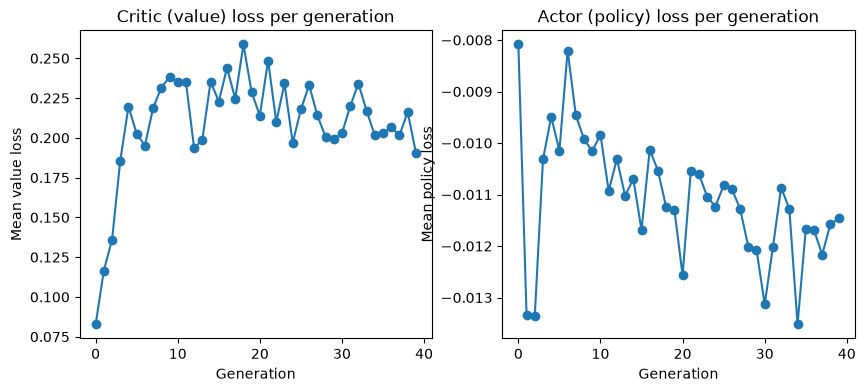

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(gens, metrics["value_loss"], marker="o")
ax1.set(xlabel="Generation", ylabel="Mean value loss", title="Critic (value) loss per generation")
ax2.plot(gens, metrics["policy_loss"], marker="o")
ax2.set(xlabel="Generation", ylabel="Mean policy loss", title="Actor (policy) loss per generation")
save(fig, "loss.png")

### Entropy
Entropy measures how spread out the policy's action probabilities are. It starts near the maximum (the dashed line, where every action is equally likely) and should drop as the agent gets more confident about what to do. A slow, steady drop is what we want. If it crashes to near zero early on, the agent stopped exploring too soon, and raising `ENT_COEF` can help.

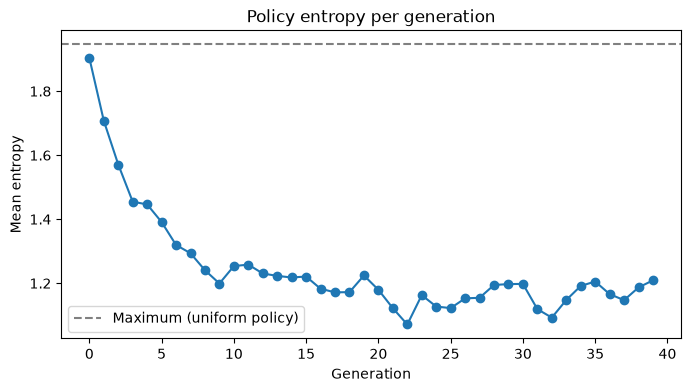

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["entropy"], marker="o")
ax.axhline(np.log(ppo_agent.action_space.n), color="gray", linestyle="--", label="Maximum (uniform policy)")
ax.set(xlabel="Generation", ylabel="Mean entropy", title="Policy entropy per generation")
ax.legend()
save(fig, "entropy.png")

### Average Reward
Both lines should climb over training as the agent gets better at picking off enemies. The blue line is AgileRL's evaluation during training, and the orange one is our checkpoint evaluation on the outro scenario, with the shaded band showing the standard deviation.

That band can be pretty wide, because episodes can go very differently: the agent might pick off enemies one by one and survive the full minute, or waste its ammo early and get swarmed. With only a handful of episodes per checkpoint, one bad episode moves the average a lot. These rewards also include the shaping penalties, so they come out a little lower than the number of kills. Since the two lines use different scenarios and different numbers of episodes, it's best to compare checkpoints within the same line rather than across them.

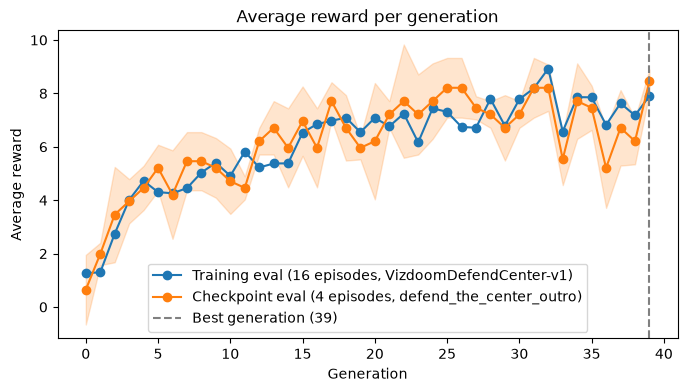

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["eval_fitness"], marker="o", label=f"Training eval ({INIT_HP['EVAL_LOOP'] * NUM_ENVS} episodes, {ENV_NAME})")
(line,) = ax.plot(gens, metrics["ckpt_eval_mean"], marker="o", label=f"Checkpoint eval ({EVAL_EPISODES} episodes, {SCENARIO_NAME})")
ax.fill_between(gens, metrics["ckpt_eval_mean"] - metrics["ckpt_eval_std"],
                metrics["ckpt_eval_mean"] + metrics["ckpt_eval_std"], color=line.get_color(), alpha=0.2)
ax.axvline(best_gen, color="gray", linestyle="--", label=f"Best generation ({best_gen})")
ax.set(xlabel="Generation", ylabel="Average reward", title="Average reward per generation")
ax.legend()
save(fig, "average_reward.png")

### Training Score
This is the average score of the training episodes in each generation. Unlike DQN, there's no epsilon here: the agent plays the training episodes the same way it plays evaluation ones, by sampling from its policy. So this line should follow the evaluation lines pretty closely, just smoother, since each point averages over a lot more episodes.

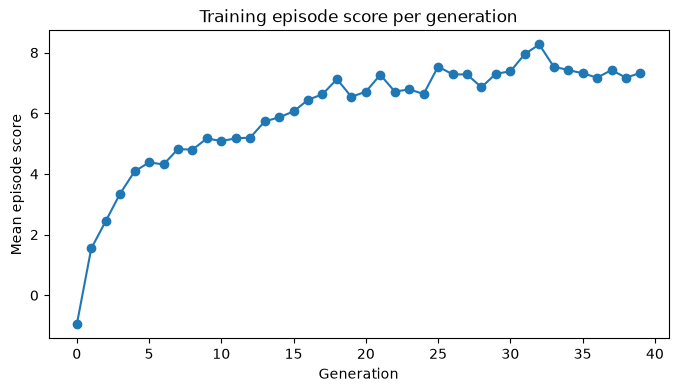

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(gens, metrics["train_score"], marker="o")
ax.set(xlabel="Generation", ylabel="Mean episode score", title="Training episode score per generation")
save(fig, "training_score.png")

### Test Runs
A well trained agent should land most of its shots and rack up a good number of kills, with the best runs getting close to the 26 kill limit. Episodes that last the full 60 seconds (around 525 agent steps) mean it survived until the clock ran out, and shorter ones mean it got overrun. Don't be surprised if the average test reward comes out a bit lower than the best checkpoint's evaluation score. We picked the best checkpoint based on only a few episodes each, so some of its score was probably just luck, and the fresh test runs give a more honest number.

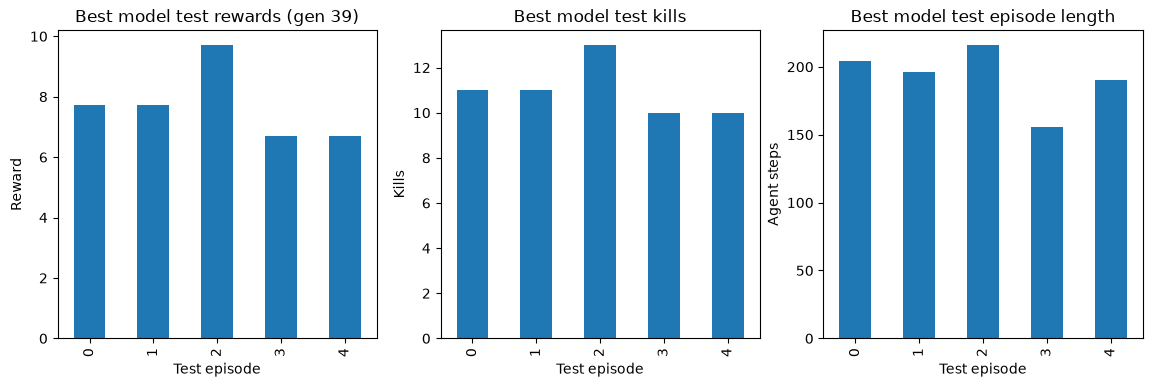

In [29]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
test_runs["reward"].plot.bar(ax=ax1, xlabel="Test episode", ylabel="Reward", title=f"Best model test rewards (gen {best_gen})")
test_runs["kills"].plot.bar(ax=ax2, xlabel="Test episode", ylabel="Kills", title="Best model test kills")
test_runs["length"].plot.bar(ax=ax3, xlabel="Test episode", ylabel="Agent steps", title="Best model test episode length")
save(fig, "test_runs.png")

### Action Distribution
First we give each action a readable name, like `TURN_LEFT+ATTACK` or `NOOP`, using the button combinations ViZDoom assigned to each action.

In [30]:
names_env = make_env(scenario_cfg)
buttons = [b.name for b in names_env.unwrapped.game.get_available_buttons()]
action_names = []
for combo in names_env.unwrapped.button_map:
    pressed = [button for button, on in zip(buttons, combo) if on]
    action_names.append("+".join(pressed) if pressed else "NOOP")
names_env.close()
action_names

['NOOP',
 'ATTACK',
 'TURN_RIGHT',
 'TURN_RIGHT+ATTACK',
 'TURN_LEFT',
 'TURN_LEFT+ATTACK',
 'TURN_LEFT+TURN_RIGHT']

With only 7 actions the chart is easy to read. You'd expect a good agent to spend a lot of its time turning to sweep the room, and to fire only when an enemy is lined up, since every bullet counts. Turning and firing at the same time is handy for clipping an enemy on the way past. The exact mix tends to change from run to run, so don't read too much into it.

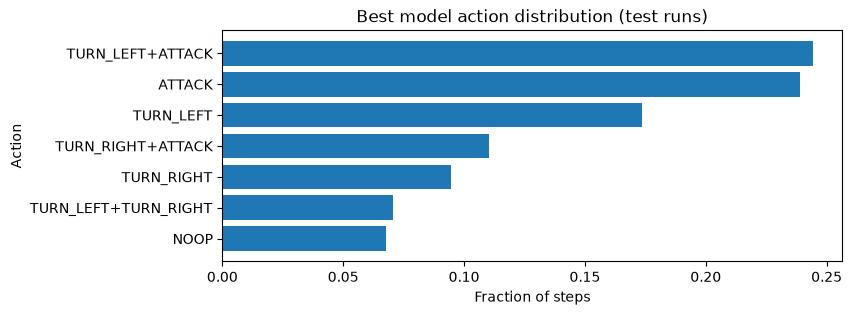

In [31]:
all_actions = np.concatenate(test_runs["actions"].to_list())
freq = pd.Series([action_names[a] for a in all_actions]).value_counts(normalize=True, ascending=True)
fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(freq))))
ax.barh(freq.index, freq.values)
ax.set(xlabel="Fraction of steps", ylabel="Action", title="Best model action distribution (test runs)")
save(fig, "test_action_distribution.png")

# Recording
Finally, let's get some video of the agent in action! This is the most involved part of the notebook, since we record ViZDoom's own demo files and then replay them at a much higher resolution.

## Recording Helpers
ViZDoom can record an episode to a `.lmp` demo file, which only stores the player's inputs, so it's tiny. The catch is that the Gymnasium wrapper doesn't expose this, so `reset_with_lmp` temporarily swaps out the environment's reset so it starts a recorded episode instead. The demo only gets written once the next episode starts, which is what `flush_lmp` is for. One gotcha: ViZDoom hangs forever if the demo's file path is longer than about 112 characters, which is easy to hit with a deep folder like this one, so we hand it a path relative to the working directory instead. Locally that's the notebook's folder, so the paths stay short. On Colab with Google Drive the working directory is `/content`, so the paths are longer: recording just the best model still fits, but `RECORD_CHECKPOINTS = "all"` goes over the limit and will hang. If you want videos of every generation on Colab, run with `USE_DRIVE = False`.

In [32]:
def reset_with_lmp(env, lmp_path):
    base = env.unwrapped
    orig_reset = base.reset

    def recorded_reset(*, seed=None, options=None):
        gymnasium.Env.reset(base, seed=seed)
        game_seed = int(
            base.np_random.integers(0, np.iinfo(np.uint32).max + 1, dtype=np.uint32)
        )
        base.game.set_seed(game_seed)
        if not base.game.is_running():
            base.game.init()
        # ViZDoom hangs if the demo path is longer than ~112 characters, so pass it relative to the working directory
        base.game.new_episode(os.path.relpath(lmp_path))
        base.state = base.game.get_state()
        return base._VizdoomEnv__collect_observations(), {}

    base.reset = recorded_reset
    try:
        return env.reset()
    finally:
        base.reset = orig_reset


def flush_lmp(env):
    env.unwrapped.game.new_episode()

## Record Checkpoints
Here we play `RECORD_EPISODES` episodes with the best checkpoint (or every checkpoint, if `RECORD_CHECKPOINTS` is `"all"`) and record each one. Videos of the best model go into `artifacts/video`, and anything else stays in the run's `recordings` folder. Old videos of the best model get cleared out first, so they don't get mixed up with this run's.

In [33]:
assert RECORD_CHECKPOINTS in ("best", "all")
record_checkpoints = [best_checkpoint] if RECORD_CHECKPOINTS == "best" else checkpoints

for old in video_dir.glob("best_episode_*"):
    old.unlink()

In [34]:
record_env = make_env(scenario_cfg)
lmps = []
lmp_rewards = {}
for ckpt in record_checkpoints:
    gen = checkpoints.index(ckpt)
    out_dir, prefix = (video_dir, "best") if ckpt == best_checkpoint else (recording_dir, f"gen_{gen}")
    agent = load_agent(ckpt)
    for episode in range(RECORD_EPISODES):
        lmp = out_dir / f"{prefix}_episode_{episode}.lmp"
        obs, _ = reset_with_lmp(record_env, lmp)
        reward, _ = play(record_env, agent, obs)
        print(f"gen {gen:>2}  episode {episode}  reward={reward:.2f}  -> {lmp.name}")
        lmps.append(lmp)
        lmp_rewards[lmp] = reward
flush_lmp(record_env)
record_env.close()

/opt/miniconda3/lib/python3.13/site-packages/tensordict/_td.py:612: FutureWarning: TensorDict.to_module() is replacing an existing nn.Parameter in the destination module with a tensor leaf that is not an nn.Parameter. This historical behavior can remove the key from module.state_dict(). In tensordict v0.14, to_module() will preserve existing module parameter and buffer registrations by default. Pass preserve_module_state=False to keep the current replacement behavior, or preserve_module_state=True to opt in to the v0.14 behavior now.
  local_out = _set_tensor_dict(
/var/folders/y0/xcyn2fwj7gz4fr_vvrf29h1r0000gn/T/ipykernel_86698/426077457.py:2: UserWarning: Attribute rollout_buffer not found in checkpoint. Skipping.
  agent = PPO.load(str(path), device=device)


gen 39  episode 0  reward=5.71  -> best_episode_0.lmp
gen 39  episode 1  reward=9.71  -> best_episode_1.lmp
gen 39  episode 2  reward=6.71  -> best_episode_2.lmp


## Convert to MP4
`lmp_to_mp4` then replays the demo in a separate game at 720p with the HUD on, grabs every frame (and the audio, when there is any) and saves it as an MP4. Since we're replaying the inputs rather than saving what the agent saw, the video looks a lot better than the 84x84 grayscale the agent trained on! Episodes here can run a minute or more, and a minute of 720p frames would take over 5 GB of memory, so each frame gets written straight to the video file instead of being held onto. The videos are encoded at a constant quality (CRF 18, about the point where you can't tell it apart from the original), with the encoder tuned for Doom's flat, cartoony textures and set to its slowest, most thorough setting. That makes them several times smaller than imageio's default settings without any visible loss, which helps them fit on GitHub. On my Mac the audio comes out silent, so those videos don't have sound.

Since the encoder takes its time squeezing the file down, each demo takes a little while to convert.

In [35]:
SAMPLE_RATE = 22050
VIDEO_PARAMS = dict(  # x264 at constant quality: CRF 18 is visually lossless, and "animation" suits Doom's flat textures
    fps=35, codec="libx264", quality=None, macro_block_size=8,
    ffmpeg_params=["-crf", "18", "-preset", "veryslow", "-tune", "animation", "-movflags", "+faststart"],
)


def lmp_to_mp4(lmp_path):
    """Replay an .lmp at 720p with HUD and audio, and write it next to the .lmp as .mp4."""
    lmp_path = Path(lmp_path)
    mp4_path = lmp_path.with_suffix(".mp4")
    silent_path = lmp_path.with_name(lmp_path.stem + "_silent.mp4")
    wav_path = lmp_path.with_suffix(".wav")

    game = vzd.DoomGame()
    game.load_config(scenario_cfg)
    if DOOM_WAD:
        game.set_doom_game_path(DOOM_WAD)
    game.set_screen_resolution(vzd.ScreenResolution.RES_1280X720)
    game.set_render_hud(True)
    game.set_render_corpses(True)
    game.set_window_visible(False)
    game.set_audio_buffer_enabled(True)
    game.set_audio_sampling_rate(vzd.SamplingRate.SR_22050)
    game.set_audio_buffer_size(1)
    game.add_game_args("+snd_efx 0")
    game.set_mode(vzd.Mode.SPECTATOR)
    game.init()

    writer = imageio.get_writer(silent_path, **VIDEO_PARAMS)
    audio = []
    try:
        game.replay_episode(os.path.relpath(lmp_path))  # relative for the same path length limit as recording
        while not game.is_episode_finished():
            state = game.get_state()
            if state is not None:
                writer.append_data(np.transpose(state.screen_buffer, (1, 2, 0)))
                if state.audio_buffer is not None:
                    audio.append(state.audio_buffer)
            game.advance_action()
    finally:
        writer.close()
        game.close()

    audio = np.concatenate(audio) if audio else np.zeros(1)
    if not audio.any():  # no sound captured (e.g. on macOS): keep the silent video
        silent_path.replace(mp4_path)
        return mp4_path

    wavfile.write(wav_path, SAMPLE_RATE, audio)
    subprocess.run(
        [imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", silent_path, "-i", wav_path,
         "-c:v", "copy", "-c:a", "aac", "-shortest", mp4_path],
        check=True, capture_output=True,
    )
    silent_path.unlink()
    wav_path.unlink()
    return mp4_path

In [36]:
mp4s = [lmp_to_mp4(lmp) for lmp in lmps]
mp4s

[PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-center-ppo-AgileRL/artifacts/video/best_episode_0.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-center-ppo-AgileRL/artifacts/video/best_episode_1.mp4'),
 PosixPath('/Users/coldstart/Desktop/rl-epsilon/vizdoom-experiments/defend-the-center-ppo-AgileRL/artifacts/video/best_episode_2.mp4')]

## Preview
And here's the best agent in action! Out of the episodes we recorded, we take the one with the highest score and turn it into a GIF, so it plays right in the notebook, and on GitHub too, which won't play embedded videos. The GIF is shrunk down to keep the notebook small, but the full quality MP4s are all still in `artifacts/video`. `mp4_to_gif` builds a color palette from the video itself first, which keeps the colors looking a lot better than a GIF normally would.

best_episode_1.gif  reward=9.71  (1.3 MB)


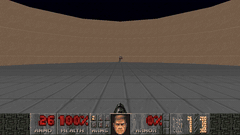

In [37]:
GIF_WIDTH = 240
GIF_FPS = 10


def mp4_to_gif(mp4_path):
    """Write a small GIF next to an MP4, with a palette built from the video so the colors hold up."""
    gif_path = Path(mp4_path).with_suffix(".gif")
    vf = (
        f"fps={GIF_FPS},scale={GIF_WIDTH}:-1:flags=lanczos,split[a][b];"
        "[a]palettegen=max_colors=128:stats_mode=diff[p];[b][p]paletteuse=dither=bayer:bayer_scale=5:diff_mode=rectangle"
    )
    subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-i", mp4_path, "-vf", vf, gif_path], check=True, capture_output=True)
    return gif_path


best_mp4 = max(
    (m for m in mp4s if m.name.startswith("best")),
    key=lambda m: lmp_rewards[m.with_suffix(".lmp")],
)
best_gif = mp4_to_gif(best_mp4)
print(f"{best_gif.name}  reward={lmp_rewards[best_mp4.with_suffix('.lmp')]:.2f}  ({best_gif.stat().st_size / 2**20:.1f} MB)")
display(Image(filename=str(best_gif)))

# Results
Here's a summary of the run, which also gets saved to `artifacts/results.json` so it's easy to compare runs later.

In [38]:
results = {
    "run": run_dir.name,
    "scenario": SCENARIO_NAME,
    "iwad": IWAD_NAME,
    "best_checkpoint": best_checkpoint.name,
    "best_generation": best_gen,
    "best_steps": int(metrics.loc[best_gen, "steps"]),
    "generations": len(checkpoints),
    "checkpoint_eval_mean": round(float(metrics.loc[best_gen, "ckpt_eval_mean"]), 4),
    "checkpoint_eval_std": round(float(metrics.loc[best_gen, "ckpt_eval_std"]), 4),
    "checkpoint_eval_rewards": [round(float(r), 4) for r in eval_rewards[best_gen]],
    "test_episodes": len(test_runs),
    "test_reward_mean": round(float(test_runs["reward"].mean()), 4),
    "test_reward_std": round(float(test_runs["reward"].std(ddof=0)), 4),
    "test_reward_min": round(float(test_runs["reward"].min()), 4),
    "test_reward_max": round(float(test_runs["reward"].max()), 4),
    "test_kills_mean": round(float(test_runs["kills"].mean()), 4),
    "test_length_mean": round(float(test_runs["length"].mean()), 4),
    "best_video": [str(m.relative_to(experiment_dir)) for m in mp4s if m.name.startswith("best")],
    "best_gif": str(best_gif.relative_to(experiment_dir)),
}
results_path.write_text(json.dumps(results, indent=2))
pd.Series(results, name="value").to_frame()

,value
run,run-20261011_152622
scenario,defend_the_center_outro
iwad,DOOM2.WAD
best_checkpoint,PPO_0_2048000.pt
best_generation,39
best_steps,2048000
generations,40
checkpoint_eval_mean,8.46
checkpoint_eval_std,0.433
checkpoint_eval_rewards,"[8.71, 8.71, 7.71, 8.71]"


# Wrapping Up
And that's it! Defend the Center is a nice fit for PPO: a small action space, and a reward that shows up right after a good shot. There's still plenty of room to push further, like training for longer, tuning the ammo penalty, giving the agent its ammo and health as extra inputs alongside the screen (it can't see the HUD), or trying AgileRL's recurrent PPO so it can remember enemies that have gone out of view. Thanks for reading!